# Laboratorul 4 — DDPM de la zero (Fashion-MNIST)

**Curs:** Generative AI · **Laboratoarele 4–5: Modele de difuzie**

**Obiectiv:** implementăm procesul direct (adăugarea de zgomot), antrenarea și generarea unui model DDPM pe imagini Fashion-MNIST, comparăm două programe de zgomot (liniar vs. cosinus) și măsurăm compromisul dintre numărul de pași și calitate (DDPM vs. DDIM).

| Sarcina | Conținut |
|:--|:--|
| 0 | Configurare (biblioteci, seed, dispozitiv) |
| 1 | Datele |
| 2 | Procesul direct (programe de zgomot, `q_sample`) |
| 3 | Rețeaua U-Net (cod dat) |
| 4 | Antrenarea cu programul liniar |
| 5 | Generarea DDPM |
| 6 | Mai puțini pași cu DDIM |
| 7 | Liniar vs. cosinus |
| Bonus | U-Net mai mic `ch=(16, 32, 64)` |
| — | Întrebări de control |

**Notații:** √ = radical; ᾱₜ = α₁·α₂·…·αₜ; N(0, I) = zgomot gaussian standard; ε_θ(xₜ, t) = zgomotul prezis de rețea. În cod pașii sunt indexați de la 0 la 999 (T = 1000).

> **Despre mediu.** Notebook-ul rulează atât pe GPU (Google Colab, T4), cât și pe serverul local (Arch Linux, micromamba, mediul `lstm-lab`, PyTorch **CPU-only**). Dispozitivul se alege automat. Pe CPU antrenarea durează mult mai mult decât cele 5–10 minute de pe T4, de aceea modelele se salvează după antrenare și se reîncarcă automat la o nouă rulare (vezi `RETRAIN`).

## 0. Configurare

Importăm bibliotecile, fixăm seed-ul (`torch.manual_seed(42)`, cerință a laboratorului: comparațiile au sens doar cu seed fix), alegem dispozitivul și definim câteva funcții ajutătoare:

- `sync()` — echivalentul lui `torch.cuda.synchronize()`, apelat înainte de fiecare citire a timpului (pe CPU nu face nimic, calculul fiind deja sincron);
- `show_grid()` — afișează un lot de imagini din intervalul [-1, 1] ca grilă.

Hiperparametrii ceruți: T = 1000, loturi de 128, Adam cu lr = 0,0002, 15 epoci.

In [1]:
import os, math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(os.cpu_count())   # folosim toate nucleele pe server

def sync():
    # Sincronizare înainte de citirea timpului (cerință pentru măsurători corecte pe GPU)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

# --- Hiperparametri (conform cerințelor) ---
T = 1000
BATCH_SIZE = 128
LR = 2e-4
EPOCHS = 15
TRAIN_SUBSET = None   # None = tot setul (60 000 imagini). Un număr mic (ex. 2048) doar pentru test rapid al codului.
RETRAIN = False       # False: dacă există deja un checkpoint salvat, îl reîncărcăm în loc să reantrenăm

OUT_DIR = "lab4_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"PyTorch {torch.__version__} | dispozitiv: {DEVICE} | fire CPU: {torch.get_num_threads()}")

def show_grid(x, nrow=8, title=None, ax=None, save_as=None, figsize=(6, 6)):
    # Afișează un tensor (B, 1, H, W) cu valori în [-1, 1] ca grilă
    x = (x.detach().cpu().clamp(-1, 1) + 1) / 2
    grid = make_grid(x, nrow=nrow, padding=2, pad_value=1.0)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    ax.axis("off")
    if title:
        ax.set_title(title)
    if own:
        plt.tight_layout()
        if save_as:
            plt.savefig(os.path.join(OUT_DIR, save_as), dpi=150, bbox_inches="tight")
        plt.show()

PyTorch 2.11.0+cu130 | dispozitiv: cuda | fire CPU: 1


## Sarcina 1. Datele

1. Încărcăm Fashion-MNIST cu `torchvision.datasets.FashionMNIST` (60 000 imagini de antrenare, 28×28, tonuri de gri, 10 clase de articole vestimentare).
2. Mărim imaginile la **32×32** cu `transforms.Pad(2)` (2 pixeli negri pe fiecare latură). Dimensiunea 32 se împarte de 3 ori la 2 (32 → 16 → 8 → 4), exact cât au nevoie cele trei niveluri de sub-eșantionare ale U-Net-ului.
3. Scalăm pixelii în **[-1, 1]**: `ToTensor()` dă [0, 1], apoi `Normalize(0.5, 0.5)` aplică (x − 0,5)/0,5. Intervalul simetric în jurul lui 0 se potrivește cu zgomotul N(0, I), spre care tinde procesul direct.
4. Creăm un `DataLoader` cu loturi de 128 și afișăm 16 imagini într-o grilă 4×4.

Număr imagini: 60000 | formă lot: (128, 1, 32, 32) | min/max: -1.0 1.0


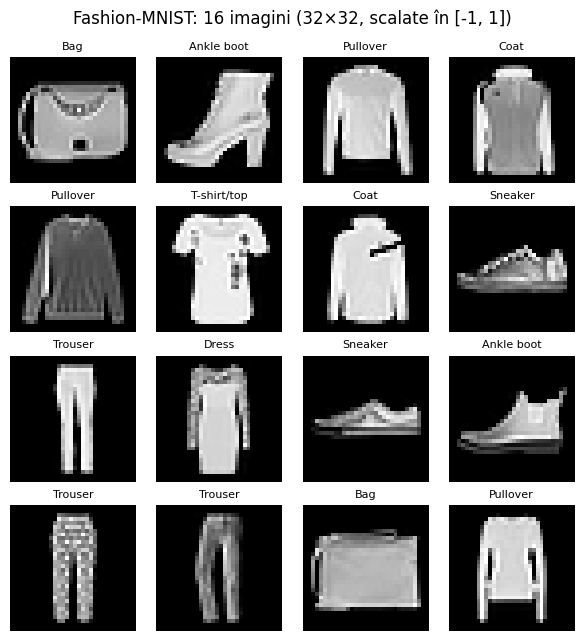

In [2]:
transform = transforms.Compose([
    transforms.Pad(2),                       # 28x28 -> 32x32
    transforms.ToTensor(),                   # [0, 1]
    transforms.Normalize((0.5,), (0.5,)),    # [-1, 1]
])

train_ds = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
CLASSES = train_ds.classes

def make_loader(seed=SEED):
    ds = train_ds if TRAIN_SUBSET is None else Subset(train_ds, range(TRAIN_SUBSET))
    g = torch.Generator().manual_seed(seed)  # ordinea loturilor reproductibilă
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                      num_workers=2, generator=g, pin_memory=(DEVICE.type == "cuda"))

train_loader = make_loader()
x_batch, y_batch = next(iter(train_loader))
print("Număr imagini:", len(train_ds), "| formă lot:", tuple(x_batch.shape),
      "| min/max:", x_batch.min().item(), x_batch.max().item())

fig, axes = plt.subplots(4, 4, figsize=(6, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow((x_batch[i, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASSES[y_batch[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Fashion-MNIST: 16 imagini (32×32, scalate în [-1, 1])")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "s1_grila_date.png"), dpi=150)
plt.show()

## Sarcina 2. Procesul direct

Procesul direct adaugă treptat zgomot gaussian: q(xₜ | xₜ₋₁) = N(√(1−βₜ)·xₜ₋₁, βₜ·I). Valorile βₜ formează **programul de zgomot**. Implementăm două programe, cu T = 1000:

- **liniar** (Ho et al., 2020): β crește uniform de la 0,0001 la 0,02 (`torch.linspace`);
- **cosinus** (Nichol & Dhariwal, 2021), cu s = 0,008:

  f(t) = cos²( ((t/T + s)/(1 + s)) · π/2 ), t = 0, 1, …, T;  ᾱₜ = f(t)/f(0);  βₜ = 1 − ᾱₜ/ᾱₜ₋₁, limitat superior la 0,999.

Pentru fiecare program calculăm αₜ = 1 − βₜ și produsul cumulat ᾱₜ (`torch.cumprod`). Calculele se fac în `float64` (produsul a 1000 de numere subunitare pierde precizie în `float32`), apoi convertim la `float32`.

Deoarece o sumă de zgomote gaussiene independente este tot gaussiană, putem sări direct la pasul t:

  **xₜ = √ᾱₜ · x₀ + √(1 − ᾱₜ) · ε**,  ε ~ N(0, I)

Aceasta este funcția `q_sample(x0, t, eps)`. √ᾱₜ este „cât semnal rămâne”, √(1−ᾱₜ) este „cât zgomot s-a adăugat”.

In [3]:
def make_schedule(kind, T=T, s=0.008):
    # Întoarce un dicționar cu betas, alphas, alphas_cumprod și rădăcinile utile, pe DEVICE
    if kind == "linear":
        betas = torch.linspace(1e-4, 0.02, T, dtype=torch.float64)
    elif kind == "cosine":
        t = torch.arange(T + 1, dtype=torch.float64)
        f = torch.cos(((t / T + s) / (1 + s)) * math.pi / 2) ** 2
        abar_f = f / f[0]
        betas = (1 - abar_f[1:] / abar_f[:-1]).clamp(max=0.999)
    else:
        raise ValueError(kind)
    alphas = 1.0 - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)          # ᾱ_t
    sched = {
        "betas": betas,
        "alphas": alphas,
        "alphas_cumprod": alphas_cumprod,
        "sqrt_abar": torch.sqrt(alphas_cumprod),            # √ᾱ_t
        "sqrt_1m_abar": torch.sqrt(1.0 - alphas_cumprod),   # √(1-ᾱ_t)
    }
    sched = {k: v.float().to(DEVICE) for k, v in sched.items()}
    sched["kind"] = kind
    return sched

def extract(a, t, x_shape):
    # Ia a[t] pentru fiecare element din lot și îl transformă în (B, 1, 1, 1) pentru broadcasting
    return a[t].view(-1, *([1] * (len(x_shape) - 1)))

def q_sample(x0, t, eps, sched):
    # Procesul direct într-un singur pas: x_t = √ᾱ_t·x0 + √(1-ᾱ_t)·ε
    return extract(sched["sqrt_abar"], t, x0.shape) * x0 + extract(sched["sqrt_1m_abar"], t, x0.shape) * eps

sched_lin = make_schedule("linear")
sched_cos = make_schedule("cosine")
for s_ in (sched_lin, sched_cos):
    print(f"{s_['kind']:7s}: beta in [{s_['betas'].min():.5f}, {s_['betas'].max():.5f}], "
          f"ᾱ_0 = {s_['alphas_cumprod'][0]:.5f}, ᾱ_999 = {s_['alphas_cumprod'][-1]:.2e}")

linear : beta in [0.00010, 0.02000], ᾱ_0 = 0.99990, ᾱ_999 = 4.04e-05
cosine : beta in [0.00004, 0.99900], ᾱ_0 = 0.99996, ᾱ_999 = 2.43e-09


### 2.1 Aceeași imagine la diferiți pași t, pentru ambele programe

Folosim **aceeași** imagine x₀ și **același** zgomot ε pentru ambele rânduri, ca diferența să vină doar din program.

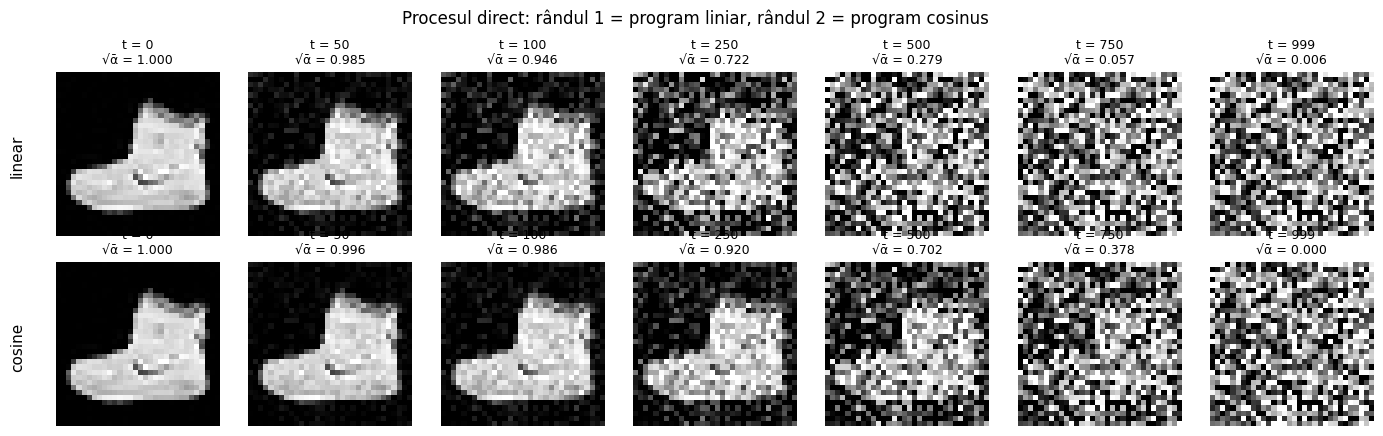

In [4]:
x0_demo = train_ds[0][0].unsqueeze(0).to(DEVICE)            # (1, 1, 32, 32)
eps_demo = torch.randn(x0_demo.shape, generator=torch.Generator().manual_seed(SEED)).to(DEVICE)
ts_demo = [0, 50, 100, 250, 500, 750, 999]

fig, axes = plt.subplots(2, len(ts_demo), figsize=(14, 4.4))
for r, sch in enumerate([sched_lin, sched_cos]):
    for c, t in enumerate(ts_demo):
        xt = q_sample(x0_demo, torch.tensor([t], device=DEVICE), eps_demo, sch)
        axes[r, c].imshow(((xt[0, 0].clamp(-1, 1) + 1) / 2).cpu(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"t = {t}\n√ᾱ = {sch['sqrt_abar'][t]:.3f}", fontsize=9)
        axes[r, c].axis("off")
    axes[r, 0].text(-8, 16, sch["kind"], rotation=90, va="center", ha="center", fontsize=11)
plt.suptitle("Procesul direct: rândul 1 = program liniar, rândul 2 = program cosinus")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "s2_proces_direct.png"), dpi=150)
plt.show()

### 2.2 Graficul √ᾱₜ în funcție de t și 2.3 pasul la care √ᾱₜ scade sub 0,5

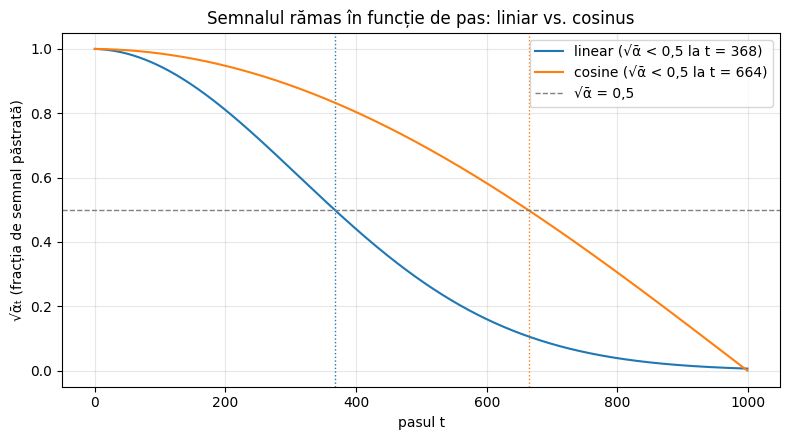

Program linear : √ᾱ_t scade sub 0,5 la pasul t = 368
Program cosine : √ᾱ_t scade sub 0,5 la pasul t = 664


In [5]:
t_axis = np.arange(T)
first_below = {}
plt.figure(figsize=(8, 4.5))
for sch, col in [(sched_lin, "tab:blue"), (sched_cos, "tab:orange")]:
    y = sch["sqrt_abar"].cpu().numpy()
    t_half = int(np.argmax(y < 0.5))       # primul t cu √ᾱ_t < 0.5
    first_below[sch["kind"]] = t_half
    plt.plot(t_axis, y, color=col, label=f"{sch['kind']} (√ᾱ < 0,5 la t = {t_half})")
    plt.axvline(t_half, color=col, ls=":", lw=1)
plt.axhline(0.5, color="gray", ls="--", lw=1, label="√ᾱ = 0,5")
plt.xlabel("pasul t")
plt.ylabel("√ᾱₜ (fracția de semnal păstrată)")
plt.title("Semnalul rămas în funcție de pas: liniar vs. cosinus")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "s2_sqrt_abar.png"), dpi=150)
plt.show()

for k, v in first_below.items():
    print(f"Program {k:7s}: √ᾱ_t scade sub 0,5 la pasul t = {v}")

**Interpretare.** La programul liniar semnalul scade repede: √ᾱₜ coboară sub 0,5 mult mai devreme, iar în ultima parte a traiectoriei imaginea este practic zgomot pur (mulți pași „irosiți”). Programul cosinus distruge informația mai lent și mai uniform, deci rețeaua vede mai multe exemple cu niveluri intermediare de zgomot, unde se învață structura imaginii.

## Sarcina 3. Rețeaua (cod dat)

U-Net mic cu 3 niveluri (32, 64, 128 canale), blocuri reziduale, conexiuni skip prin concatenare și încorporare sinusoidală a pasului t.

> **Notă.** În PDF câteva caractere s-au pierdut la extragerea textului și codul nu rulează exact așa cum apare. Corecturile (fără a schimba arhitectura):
> - `t.float()[: None]` → `t.float()[:, None]` și `freqs[None,]` → `freqs[None, :]`;
> - `self.t_proj(temb)[: None, None]` → `self.t_proj(temb)[:, :, None, None]` (adaugă dimensiunile spațiale pentru broadcasting);
> - `self.self.out` → `self.out`.

Comentariile marcate **[PASUL t]**, **[SKIP]** și **[REZIDUAL]** arată unde intră pasul t, unde sunt conexiunile skip și unde sunt conexiunile reziduale (cerința 3.3).

In [6]:
def time_embedding(t, dim=128):
    # [PASUL t] t: tensor (B,) cu pașii -> încorporare sinusoidală (B, dim), ca în Transformer
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)

class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, c_out)          # [PASUL t] proiecția încorporării lui t pe canale
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        # [REZIDUAL] ramura scurtă: identitate sau conv 1x1 dacă se schimbă numărul de canale
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]    # [PASUL t] t este adunat la hărțile de trăsături
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)                        # [REZIDUAL] conexiune reziduală: ieșire = F(x) + x

class UNet(nn.Module):
    def __init__(self, ch=(32, 64, 128), t_dim=128):
        super().__init__()
        # [PASUL t] MLP care prelucrează încorporarea sinusoidală a lui t
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inp = nn.Conv2d(1, ch[0], 3, padding=1)
        self.down1 = ResBlock(ch[0], ch[0])
        self.down2 = ResBlock(ch[0], ch[1])
        self.down3 = ResBlock(ch[1], ch[2])
        self.mid = ResBlock(ch[2], ch[2])
        self.up3 = ResBlock(2 * ch[2], ch[1])   # 2*ch: intrare = upsample + skip concatenat
        self.up2 = ResBlock(2 * ch[1], ch[0])
        self.up1 = ResBlock(2 * ch[0], ch[0])
        self.out = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x, t):
        temb = self.t_mlp(time_embedding(t))    # [PASUL t] încorporarea e trimisă fiecărui ResBlock
        x = self.inp(x)
        s1 = self.down1(x, temb)                           # 32x32  (salvat pentru [SKIP])
        s2 = self.down2(F.avg_pool2d(s1, 2), temb)         # 16x16  (salvat pentru [SKIP])
        s3 = self.down3(F.avg_pool2d(s2, 2), temb)         # 8x8    (salvat pentru [SKIP])
        h = self.mid(F.avg_pool2d(s3, 2), temb)            # 4x4    (gâtul rețelei)
        up = lambda z: F.interpolate(z, scale_factor=2)
        h = self.up3(torch.cat([up(h), s3], dim=1), temb)  # [SKIP] concatenare cu s3
        h = self.up2(torch.cat([up(h), s2], dim=1), temb)  # [SKIP] concatenare cu s2
        h = self.up1(torch.cat([up(h), s1], dim=1), temb)  # [SKIP] concatenare cu s1
        return self.out(h)                                 # zgomotul prezis ε_θ(x_t, t)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

### Verificări cerute
1. Ieșirea are aceeași formă ca intrarea: `(8, 1, 32, 32)` — rețeaua prezice un zgomot pentru fiecare pixel.
2. Numărul de parametri (așteptat: aproximativ 1 milion).

In [7]:
_net = UNet()
_out = _net(torch.randn(8, 1, 32, 32), torch.randint(0, 1000, (8,)))
print("Formă ieșire:", tuple(_out.shape))
assert _out.shape == (8, 1, 32, 32)
print(f"Număr de parametri UNet(ch=(32, 64, 128)): {count_params(_net):,}")
for name, mod in _net.named_children():
    print(f"  {name:6s} {count_params(mod):>9,}")
del _net, _out

Formă ieșire: (8, 1, 32, 32)
Număr de parametri UNet(ch=(32, 64, 128)): 979,585
  t_mlp     33,024
  inp          320
  down1     22,752
  down2     65,984
  down3    246,656
  mid      312,192
  up3      209,792
  up2       54,720
  up1       34,112
  out           33


## Sarcina 4. Antrenarea cu programul liniar

Algoritmul 1 din Ho et al. (2020). La fiecare lot:
1. alegem pentru fiecare imagine un pas t aleator, uniform din {0, …, 999};
2. generăm ε ~ N(0, I);
3. calculăm xₜ cu `q_sample` (un singur pas, fără a parcurge pașii anteriori);
4. rețeaua prezice ε, iar pierderea este **L = media(‖ε − ε_θ(xₜ, t)‖²)** (`F.mse_loss`).

Setări: Adam, lr = 0,0002, loturi de 128, 15 epoci. Salvăm pierderea medie pe epocă și modelul (`torch.save`). Funcția `train_ddpm` este generală — o refolosim la Sarcina 7 (cosinus) și la Bonus (rețea mai mică). Dacă checkpoint-ul există deja și `RETRAIN = False`, modelul se reîncarcă (util dacă sesiunea se închide).

In [8]:
def train_ddpm(sched, name, ch=(32, 64, 128), epochs=EPOCHS, seed=SEED):
    path = os.path.join(OUT_DIR, f"ddpm_{name}.pt")
    if os.path.exists(path) and not RETRAIN:
        ckpt = torch.load(path, map_location=DEVICE)
        model = UNet(ch=tuple(ckpt["ch"])).to(DEVICE)
        model.load_state_dict(ckpt["model"])
        print(f"[{name}] model reîncărcat din {path} (antrenat în {ckpt['train_time']:.0f} s)")
        return model, ckpt["losses"], ckpt["train_time"]

    set_seed(seed)                               # aceeași inițializare și același flux aleator
    model = UNet(ch=ch).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loader = make_loader(seed)
    losses = []
    sync(); t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        total, n = 0.0, 0
        for x0, _ in tqdm(loader, desc=f"[{name}] epoca {ep}/{epochs}", leave=False):
            x0 = x0.to(DEVICE, non_blocking=True)
            t = torch.randint(0, T, (x0.size(0),), device=DEVICE)    # 1. t aleator
            eps = torch.randn_like(x0)                               # 2. zgomot
            xt = q_sample(x0, t, eps, sched)                         # 3. imaginea zgomotoasă
            loss = F.mse_loss(model(xt, t), eps)                     # 4. MSE între ε și ε_θ
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.item() * x0.size(0)
            n += x0.size(0)
        losses.append(total / n)
        sync()
        print(f"[{name}] epoca {ep:2d}/{epochs}  pierdere medie = {losses[-1]:.5f}  "
              f"({time.perf_counter() - t_start:.0f} s scurse)")
    sync(); train_time = time.perf_counter() - t_start
    torch.save({"model": model.state_dict(), "losses": losses, "train_time": train_time,
                "ch": list(ch), "schedule": sched["kind"]}, path)
    print(f"[{name}] model salvat în {path}; timp total de antrenare: {train_time:.0f} s")
    return model, losses, train_time

def plot_losses(curves, title, save_as):
    plt.figure(figsize=(7, 4))
    for label, ls in curves.items():
        plt.plot(range(1, len(ls) + 1), ls, marker="o", label=label)
    plt.xlabel("epoca")
    plt.ylabel("pierdere MSE medie")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, save_as), dpi=150)
    plt.show()

[linear] epoca 1/15:   0%|          | 0/468 [00:00<?, ?it/s]

[linear] epoca  1/15  pierdere medie = 0.09391  (34 s scurse)


[linear] epoca 2/15:   0%|          | 0/468 [00:00<?, ?it/s]

[linear] epoca  2/15  pierdere medie = 0.04807  (68 s scurse)


[linear] epoca 3/15:   0%|          | 0/468 [00:00<?, ?it/s]

...

[linear] epoca 14/15:   0%|          | 0/468 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
    Exception ignored in: <function _MultiProcessingDataLoaderIter._

[linear] epoca 14/15  pierdere medie = 0.03263  (476 s scurse)


[linear] epoca 15/15:   0%|          | 0/468 [00:00<?, ?it/s]

[linear] epoca 15/15  pierdere medie = 0.03267  (510 s scurse)
[linear] model salvat în lab4_outputs/ddpm_linear.pt; timp total de antrenare: 510 s


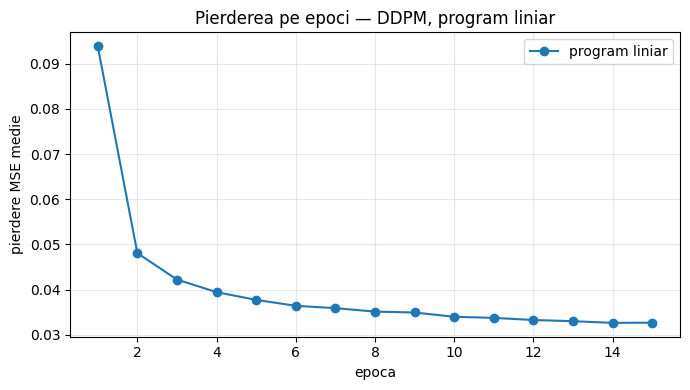

In [9]:
model_lin, losses_lin, time_lin = train_ddpm(sched_lin, "linear")
plot_losses({"program liniar": losses_lin}, "Pierderea pe epoci — DDPM, program liniar", "s4_pierdere_liniar.png")

## Sarcina 5. Generarea DDPM

Algoritmul 2 din Ho et al. (2020), cu σₜ² = βₜ. Pornim de la zgomot pur x₉₉₉ ~ N(0, I) și parcurgem t = 999, 998, …, 0:

  **xₜ₋₁ = (1/√αₜ) · ( xₜ − (βₜ/√(1 − ᾱₜ)) · ε_θ(xₜ, t) ) + σₜ · z**,  z ~ N(0, I)

La ultimul pas (t = 0) nu adăugăm zgomot (z = 0). Folosim `torch.no_grad()` (fără gradienți: mai rapid, mai puțină memorie) și `model.eval()`.

Fixăm **un singur zgomot de pornire `x_T_fixed`** (64 de imagini, seed 42), refolosit la Sarcinile 5, 6 și 7, ca toate metodele să plece din același punct.

DDPM, 1000 de pași, 64 de imagini: 11.9 s


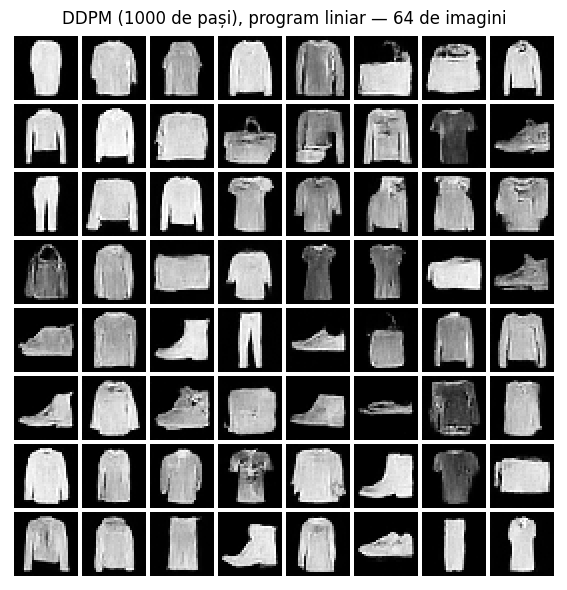

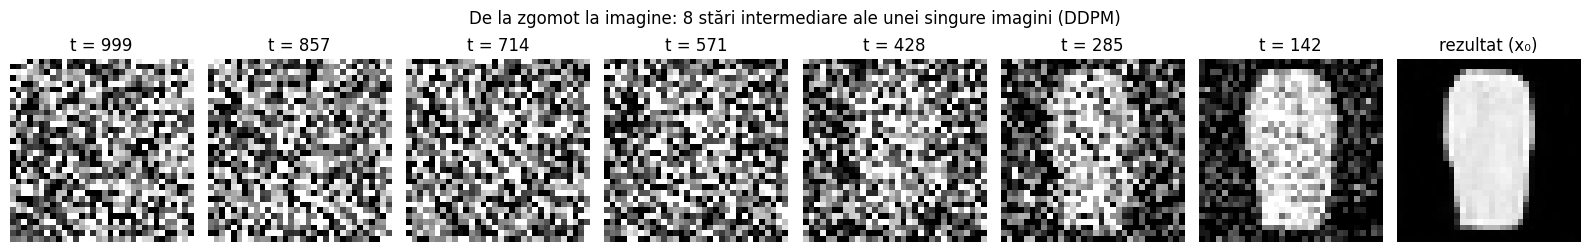

In [10]:
x_T_fixed = torch.randn(64, 1, 32, 32, generator=torch.Generator().manual_seed(SEED))

@torch.no_grad()
def sample_ddpm(model, sched, x_T, record_ts=()):
    model.eval()
    x = x_T.to(DEVICE).clone()
    traj = {}
    for t in range(T - 1, -1, -1):
        if t in record_ts:
            traj[t] = x[0].cpu().clone()                 # starea x_t a primei imagini
        tt = torch.full((x.size(0),), t, device=DEVICE, dtype=torch.long)
        eps = model(x, tt)
        beta, alpha, abar = sched["betas"][t], sched["alphas"][t], sched["alphas_cumprod"][t]
        mean = (x - beta / torch.sqrt(1 - abar) * eps) / torch.sqrt(alpha)
        if t > 0:
            x = mean + torch.sqrt(beta) * torch.randn_like(x)   # σ_t = √β_t
        else:
            x = mean                                            # ultimul pas: fără zgomot
    traj["final"] = x[0].cpu().clone()
    return x.cpu(), traj

record_ts = [999, 857, 714, 571, 428, 285, 142]            # 7 stări + rezultatul final = 8 stări
set_seed()                                                 # zgomotul z de la fiecare pas e reproductibil
sync(); t0 = time.perf_counter()
samples_ddpm, traj = sample_ddpm(model_lin, sched_lin, x_T_fixed, record_ts)
sync(); time_ddpm = time.perf_counter() - t0
print(f"DDPM, 1000 de pași, 64 de imagini: {time_ddpm:.1f} s")

show_grid(samples_ddpm, nrow=8, title="DDPM (1000 de pași), program liniar — 64 de imagini",
          save_as="s5_ddpm_grila64.png")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, key in zip(axes, record_ts + ["final"]):
    ax.imshow(((traj[key][0].clamp(-1, 1) + 1) / 2), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {key}" if key != "final" else "rezultat (x₀)")
    ax.axis("off")
plt.suptitle("De la zgomot la imagine: 8 stări intermediare ale unei singure imagini (DDPM)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "s5_ddpm_stari_intermediare.png"), dpi=150)
plt.show()

## Sarcina 6. Mai puțini pași cu DDIM

DDIM (Song, Meng, Ermon, 2021) folosește **aceeași rețea antrenată**, dar o eșantionare deterministă care poate sări peste pași. Pe un șir rar de pași (`torch.linspace(999, 0, n).long()`), pentru fiecare pereche consecutivă t → t':

  x̂₀ = ( xₜ − √(1 − ᾱₜ) · ε_θ(xₜ, t) ) / √ᾱₜ   (estimarea imaginii curate)
  xₜ' = √ᾱₜ' · x̂₀ + √(1 − ᾱₜ') · ε_θ(xₜ, t)   (o „re-zgomotăm” la nivelul pasului t')

La ultimul pas, rezultatul este direct x̂₀. Generăm câte 64 de imagini cu 10, 20, 50, 200 și 1000 de pași, din același zgomot `x_T_fixed`, și măsurăm timpul cu `time.perf_counter()` (cu sincronizare înainte de fiecare citire).

DDIM 1000 pași: 11.94 s pentru 64 de imagini
DDIM  200 pași: 2.37 s pentru 64 de imagini
DDIM   50 pași: 0.59 s pentru 64 de imagini
DDIM   20 pași: 0.24 s pentru 64 de imagini
DDIM   10 pași: 0.12 s pentru 64 de imagini


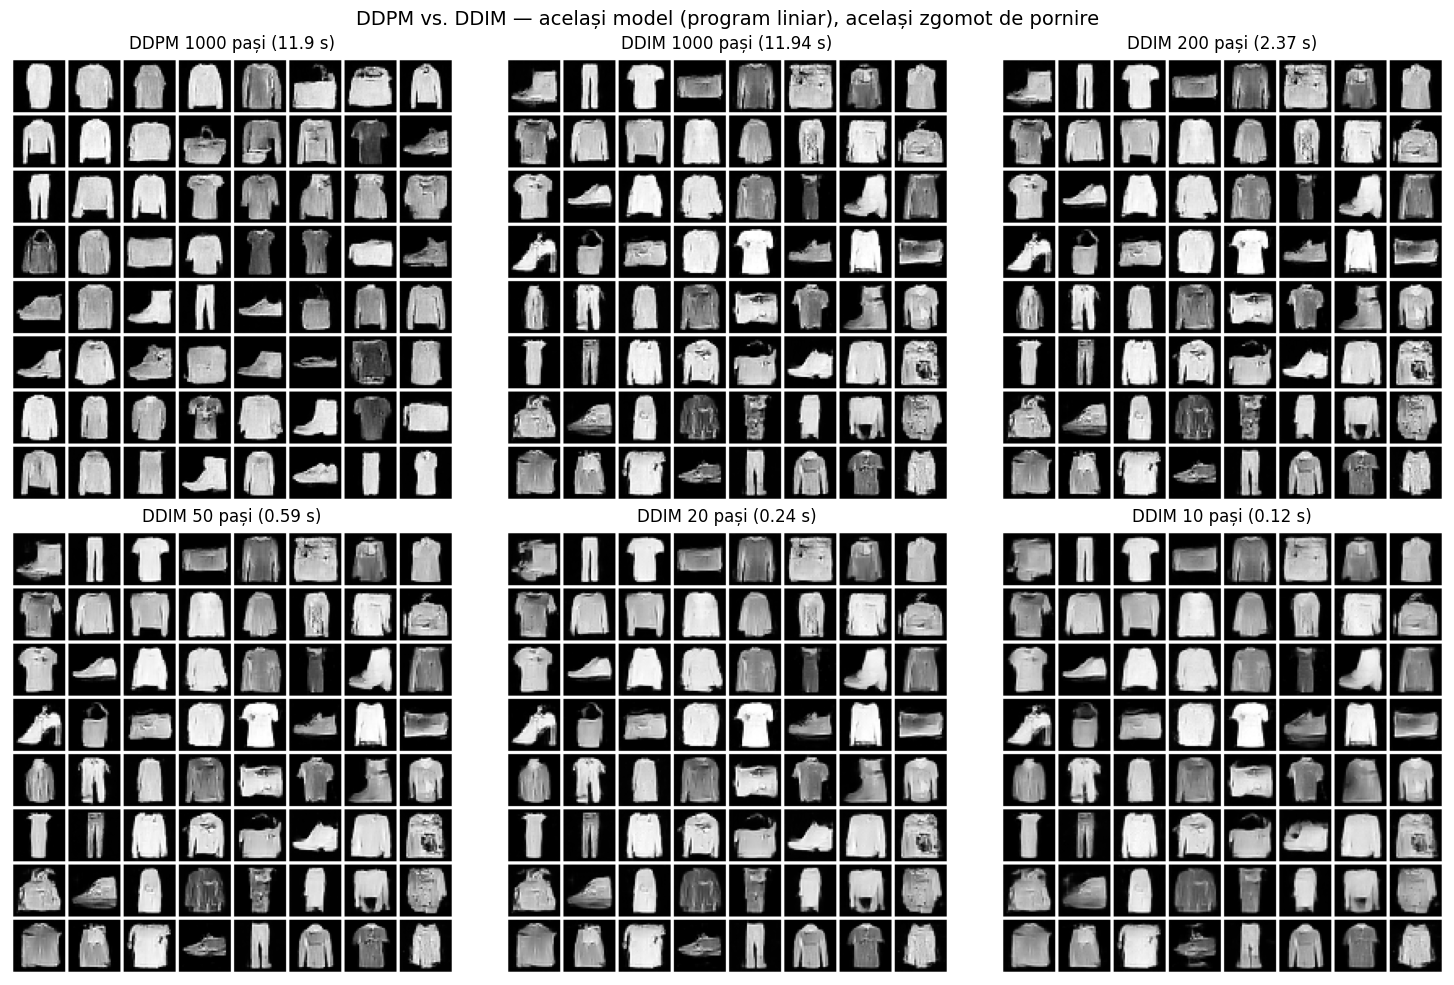

In [11]:
@torch.no_grad()
def sample_ddim(model, sched, n_steps, x_T):
    model.eval()
    ts = torch.linspace(T - 1, 0, n_steps).long().tolist()
    abar = sched["alphas_cumprod"]
    x = x_T.to(DEVICE).clone()
    for i, t in enumerate(ts):
        tt = torch.full((x.size(0),), t, device=DEVICE, dtype=torch.long)
        eps = model(x, tt)
        x0_hat = (x - torch.sqrt(1 - abar[t]) * eps) / torch.sqrt(abar[t])
        if i == len(ts) - 1:
            x = x0_hat                                   # ultimul pas: direct x̂0
        else:
            t_next = ts[i + 1]
            x = torch.sqrt(abar[t_next]) * x0_hat + torch.sqrt(1 - abar[t_next]) * eps
    return x.cpu()

def timed(fn, *args):
    sync(); t0 = time.perf_counter()
    out = fn(*args)
    sync()
    return out, time.perf_counter() - t0

ddim_steps = [1000, 200, 50, 20, 10]
ddim_samples, ddim_times = {}, {}
for n in ddim_steps:
    ddim_samples[n], ddim_times[n] = timed(sample_ddim, model_lin, sched_lin, n, x_T_fixed)
    print(f"DDIM {n:4d} pași: {ddim_times[n]:.2f} s pentru 64 de imagini")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
show_grid(samples_ddpm, ax=axes[0, 0], title=f"DDPM 1000 pași ({time_ddpm:.1f} s)")
for ax, n in zip(axes.flat[1:], ddim_steps):
    show_grid(ddim_samples[n], ax=ax, title=f"DDIM {n} pași ({ddim_times[n]:.2f} s)")
plt.suptitle("DDPM vs. DDIM — același model (program liniar), același zgomot de pornire", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "s6_ddpm_vs_ddim.png"), dpi=130)
plt.show()

### Tabelul DDPM / DDIM

Timpii se completează automat. Coloanele **Calitate vizuală (1–5)** și **Observații** se completează de voi, după grilele de mai sus (editați dicționarele `calitate` și `observatii`, apoi rulați din nou celula).

In [12]:
# >>> Completați după inspectarea vizuală a grilelor (1 = foarte slab, 5 = foarte bun) <<<
calitate = {("DDPM", 1000): "", ("DDIM", 1000): "", ("DDIM", 200): "",
            ("DDIM", 50): "", ("DDIM", 20): "", ("DDIM", 10): ""}
observatii = {("DDPM", 1000): "", ("DDIM", 1000): "", ("DDIM", 200): "",
              ("DDIM", 50): "", ("DDIM", 20): "", ("DDIM", 10): ""}

rows = [("DDPM", 1000, time_ddpm)] + [("DDIM", n, ddim_times[n]) for n in ddim_steps]
table_s6 = pd.DataFrame([{
    "Metodă": m, "Pași": n, "Timp pentru 64 de imagini (s)": round(tm, 2),
    "Accelerare față de DDPM": f"×{time_ddpm / tm:.1f}",
    "Calitate vizuală (1-5)": calitate[(m, n)], "Observații": observatii[(m, n)],
} for m, n, tm in rows])
table_s6.to_csv(os.path.join(OUT_DIR, "s6_tabel_ddpm_ddim.csv"), index=False)
table_s6

,Metodă,Pași,Timp pentru 64 de imagini (s),Accelerare față de DDPM,Calitate vizuală (1-5),Observații
0,DDPM,1000,11.86,×1.0,,
1,DDIM,1000,11.94,×1.0,,
2,DDIM,200,2.37,×5.0,,
3,DDIM,50,0.59,×20.0,,
4,DDIM,20,0.24,×49.9,,
5,DDIM,10,0.12,×99.0,,


## Sarcina 7. Liniar vs. cosinus

Antrenăm un al doilea model, **identic** (aceeași arhitectură, 15 epoci, seed 42, aceeași ordine a loturilor), dar cu programul cosinus — singurul parametru schimbat. Apoi:
1. generăm câte 64 de imagini cu ambele modele, cu DDIM la 50 și la 20 de pași, din același zgomot de pornire;
2. punem grilele alături și notăm calitatea vizuală (1–5);
3. trasăm curbele de pierdere pe același grafic.

> Valorile pierderii **nu** sunt direct comparabile între programe (media se face peste niveluri de zgomot diferite). Comparăm modelele după imaginile generate.

In [13]:
model_cos, losses_cos, time_cos = train_ddpm(sched_cos, "cosine")

[cosine] epoca 1/15:   0%|          | 0/468 [00:00<?, ?it/s]

[cosine] epoca  1/15  pierdere medie = 0.14207  (33 s scurse)


[cosine] epoca 2/15:   0%|          | 0/468 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError: can only test a child processException ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[cosine] epoca  2/15  pierdere medie = 0.08225  (67 s scurse)


...

[cosine] epoca 14/15:   0%|          | 0/468 [00:00<?, ?it/s]

[cosine] epoca 14/15  pierdere medie = 0.05904  (473 s scurse)


[cosine] epoca 15/15:   0%|          | 0/468 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[cosine] epoca 15/15  pierdere medie = 0.05892  (506 s scurse)
[cosine] model salvat în lab4_outputs/ddpm_cosine.pt; timp total de antrenare: 506 s


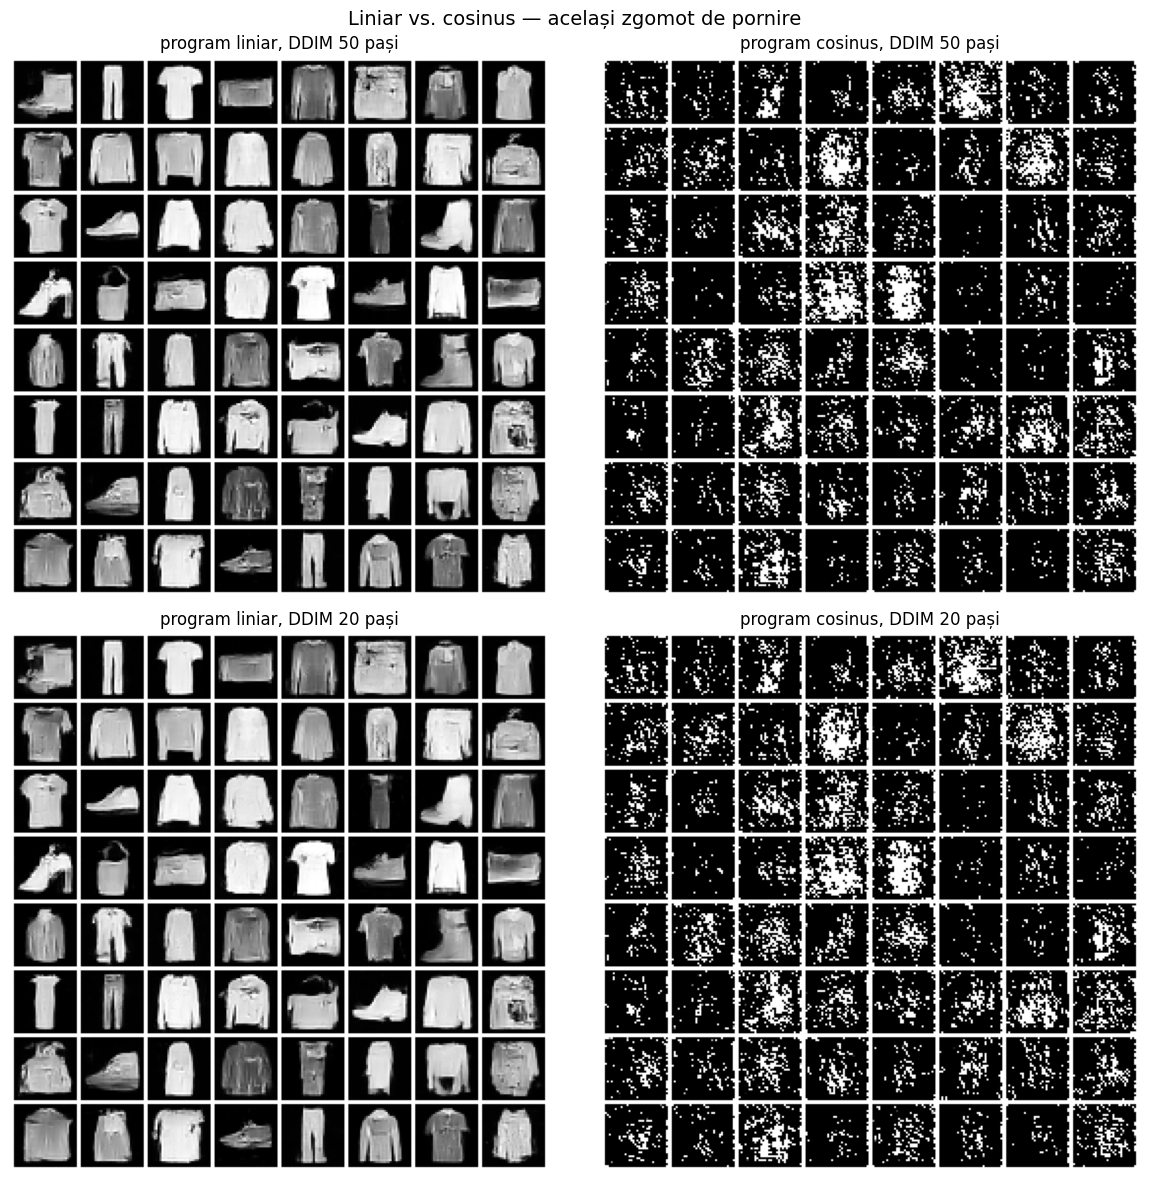

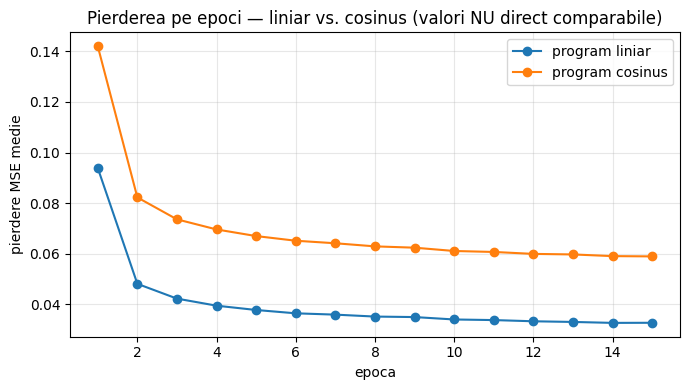

In [14]:
cmp = {}
for name, mdl, sch in [("liniar", model_lin, sched_lin), ("cosinus", model_cos, sched_cos)]:
    for n in (50, 20):
        cmp[(name, n)] = sample_ddim(mdl, sch, n, x_T_fixed)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for r, n in enumerate((50, 20)):
    for c, name in enumerate(("liniar", "cosinus")):
        show_grid(cmp[(name, n)], ax=axes[r, c], title=f"program {name}, DDIM {n} pași")
plt.suptitle("Liniar vs. cosinus — același zgomot de pornire", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "s7_liniar_vs_cosinus.png"), dpi=130)
plt.show()

plot_losses({"program liniar": losses_lin, "program cosinus": losses_cos},
            "Pierderea pe epoci — liniar vs. cosinus (valori NU direct comparabile)",
            "s7_pierderi_liniar_cosinus.png")

In [15]:
# >>> Completați calitatea vizuală (1-5) după grilele de mai sus <<<
calitate_s7 = {("liniar", 50): "", ("cosinus", 50): "", ("liniar", 20): "", ("cosinus", 20): ""}

table_s7 = pd.DataFrame([{
    "Program": p, "Pași DDIM": n, "Calitate vizuală (1-5)": calitate_s7[(p, n)],
    "Pierdere finală (epoca 15)": round((losses_lin if p == "liniar" else losses_cos)[-1], 5),
    "Timp antrenare (s)": round(time_lin if p == "liniar" else time_cos),
} for p, n in calitate_s7])
table_s7.to_csv(os.path.join(OUT_DIR, "s7_tabel_liniar_cosinus.csv"), index=False)
table_s7

,Program,Pași DDIM,Calitate vizuală (1-5),Pierdere finală (epoca 15),Timp antrenare (s)
0,liniar,50,,0.03267,510
1,cosinus,50,,0.05892,506
2,liniar,20,,0.03267,510
3,cosinus,20,,0.05892,506


## Bonus (+1 punct). Rețea mai mică: `UNet(ch=(16, 32, 64))`

Antrenăm aceeași rețea, cu numărul de canale înjumătățit pe fiecare nivel (program liniar, aceleași setări), și comparăm numărul de parametri, timpul de antrenare și calitatea (DDIM 50 de pași, același zgomot). Numărul de parametri al convoluțiilor crește aproximativ cu pătratul numărului de canale, deci ne așteptăm la circa 4× mai puțini parametri. `GroupNorm(8, 16)` rămâne valid (16 se împarte la 8).

[linear_small] epoca 1/15:   0%|          | 0/468 [00:00<?, ?it/s]

[linear_small] epoca  1/15  pierdere medie = 0.14780  (22 s scurse)


[linear_small] epoca 2/15:   0%|          | 0/468 [00:00<?, ?it/s]

[linear_small] epoca  2/15  pierdere medie = 0.05910  (44 s scurse)


[linear_small] epoca 3/15:   0%|          | 0/468 [00:00<?, ?it/s]

...

[linear_small] epoca 14/15:   0%|          | 0/468 [00:00<?, ?it/s]

[linear_small] epoca 14/15  pierdere medie = 0.03631  (299 s scurse)


[linear_small] epoca 15/15:   0%|          | 0/468 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79fe66abc720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[linear_small] epoca 15/15  pierdere medie = 0.03627  (320 s scurse)
[linear_small] model salvat în lab4_outputs/ddpm_linear_small.pt; timp total de antrenare: 320 s


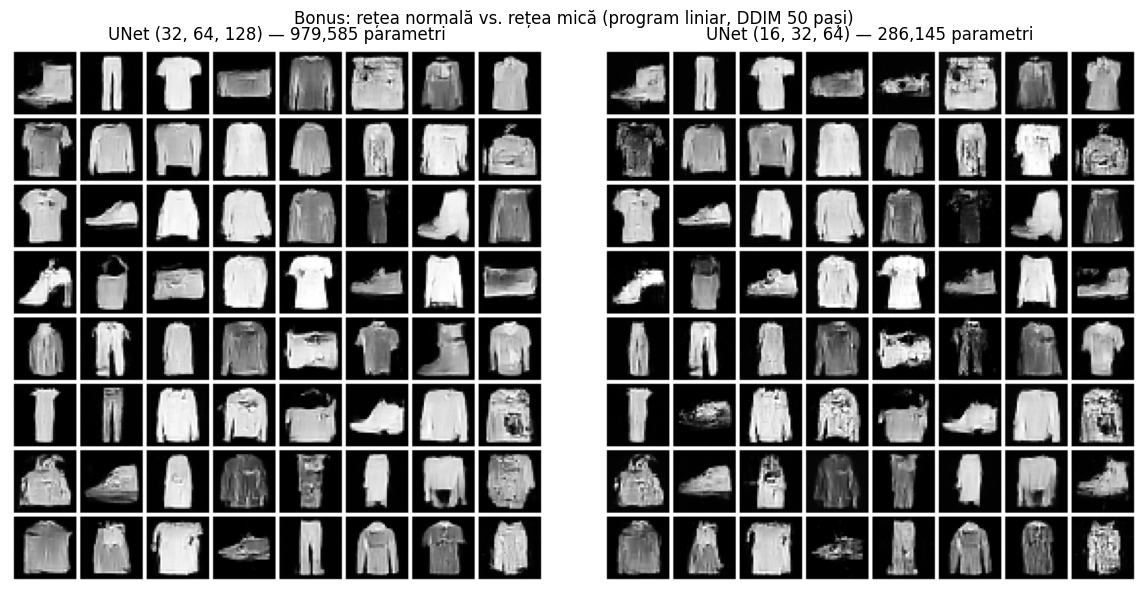

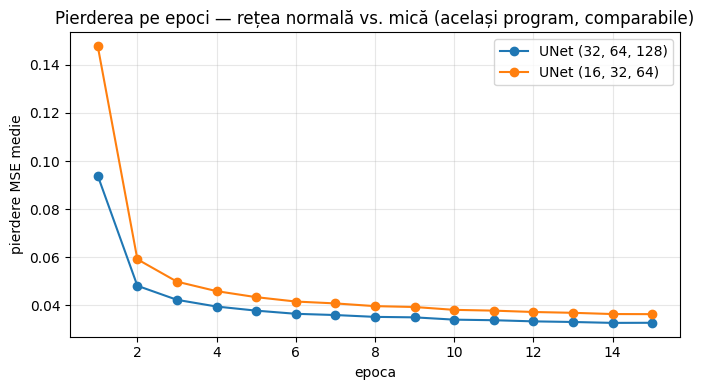

,Rețea,Parametri,Timp antrenare (s),Pierdere finală,"DDIM 50 pași, 64 imagini (s)",Calitate vizuală (1-5)
0,"UNet (32, 64, 128)",979585,510,0.03267,0.64,
1,"UNet (16, 32, 64)",286145,320,0.03627,0.26,


In [16]:
model_small, losses_small, time_small = train_ddpm(sched_lin, "linear_small", ch=(16, 32, 64))

small_50 = sample_ddim(model_small, sched_lin, 50, x_T_fixed)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
show_grid(cmp[("liniar", 50)], ax=axes[0], title=f"UNet (32, 64, 128) — {count_params(model_lin):,} parametri")
show_grid(small_50, ax=axes[1], title=f"UNet (16, 32, 64) — {count_params(model_small):,} parametri")
plt.suptitle("Bonus: rețea normală vs. rețea mică (program liniar, DDIM 50 pași)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "bonus_retea_mica.png"), dpi=130)
plt.show()

plot_losses({"UNet (32, 64, 128)": losses_lin, "UNet (16, 32, 64)": losses_small},
            "Pierderea pe epoci — rețea normală vs. mică (același program, comparabile)",
            "bonus_pierderi.png")

_, t_big = timed(sample_ddim, model_lin, sched_lin, 50, x_T_fixed)
_, t_small = timed(sample_ddim, model_small, sched_lin, 50, x_T_fixed)
calitate_bonus = {"UNet (32, 64, 128)": "", "UNet (16, 32, 64)": ""}   # >>> completați 1-5 <<<
table_bonus = pd.DataFrame([
    {"Rețea": "UNet (32, 64, 128)", "Parametri": count_params(model_lin), "Timp antrenare (s)": round(time_lin),
     "Pierdere finală": round(losses_lin[-1], 5), "DDIM 50 pași, 64 imagini (s)": round(t_big, 2),
     "Calitate vizuală (1-5)": calitate_bonus["UNet (32, 64, 128)"]},
    {"Rețea": "UNet (16, 32, 64)", "Parametri": count_params(model_small), "Timp antrenare (s)": round(time_small),
     "Pierdere finală": round(losses_small[-1], 5), "DDIM 50 pași, 64 imagini (s)": round(t_small, 2),
     "Calitate vizuală (1-5)": calitate_bonus["UNet (16, 32, 64)"]},
])
table_bonus.to_csv(os.path.join(OUT_DIR, "bonus_tabel.csv"), index=False)
table_bonus